### Welcome to the exercise about observational studies! This exercise will be hands on, and you will be able to practise the skills you developed so far!

## Propensity score matching

In this exercise, you will apply [propensity score matching](http://www.stewartschultz.com/statistics/books/Design%20of%20observational%20studies.pdf), which we discussed in lecture 6 ("Observational studies"), in order to draw conclusions from an observational study.

We will work with a by-now classic dataset from Robert LaLonde's study "[Evaluating the Econometric Evaluations of Training Programs](http://people.hbs.edu/nashraf/LaLonde_1986.pdf)" (1986).
The study investigated the effect of a job training program ("National Supported Work Demonstration") on the real earnings of an individual, a couple of years after completion of the program.
Your task is to determine the effectiveness of the "treatment" represented by the job training program.

#### Dataset description

- `treat`: 1 if the subject participated in the job training program, 0 otherwise
- `age`: the subject's age
- `educ`: years of education
- `race`: categorical variable with three possible values: Black, Hispanic, or White
- `married`: 1 if the subject was married at the time of the training program, 0 otherwise
- `nodegree`: 1 if the subject has earned no school degree, 0 otherwise
- `re74`: real earnings in 1974 (pre-treatment)
- `re75`: real earnings in 1975 (pre-treatment)
- `re78`: real earnings in 1978 (outcome)

If you want to deepen your knowledge on propensity scores and observational studies, we highly recommend Rosenbaum's excellent book on the ["Design of Observational Studies"](http://www.stewartschultz.com/statistics/books/Design%20of%20observational%20studies.pdf). Even just reading the first chapter (18 pages) will help you a lot.

In [1]:
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
%matplotlib inline

data_folder = './data/'
df = pd.read_csv(data_folder + 'lalonde.csv')

In [2]:
df.sample(10)

,id,treat,age,educ,black,hispan,married,nodegree,re74,re75,re78
307,PSID123,0,25,12,0,0,1,0,21469.650,3405.194,7981.20100
587,PSID403,0,48,12,0,0,1,0,0.000,0.000,1491.02600
380,PSID196,0,18,11,1,0,0,1,0.000,1367.806,33.98771
562,PSID378,0,30,10,0,0,1,1,0.000,0.000,3151.99100
590,PSID406,0,16,10,1,0,0,1,0.000,0.000,1730.41800
240,PSID56,0,29,8,0,0,1,1,9169.369,6352.065,20575.86000
91,NSW92,1,17,10,1,0,0,1,0.000,0.000,0.00000
538,PSID354,0,50,5,1,0,1,1,411.446,0.000,9166.33800
349,PSID165,0,30,12,0,0,1,0,7347.251,2080.355,14475.81000
242,PSID58,0,31,12,0,0,1,0,23652.270,6228.532,22403.81000


## 1. A naive analysis

Compare the distribution of the outcome variable (`re78`) between the two groups, using plots and numbers.
To summarize and compare the distributions, you may use the techniques we discussed in lecture 4 ("Descibing data") and 3 ("Visualizing data").

What might a naive "researcher" conclude from this superficial analysis?

Text(0.5, 1.0, 'Real earnings with and without treatment')

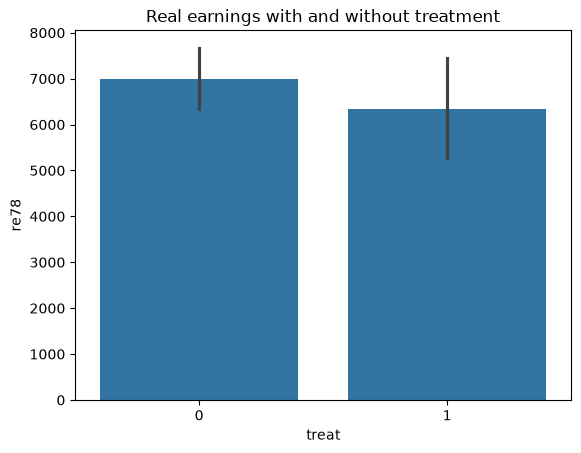

In [22]:
ax = sns.barplot(x="treat", y="re78", data=df)
ax.set_title("Real earnings with and without treatment")

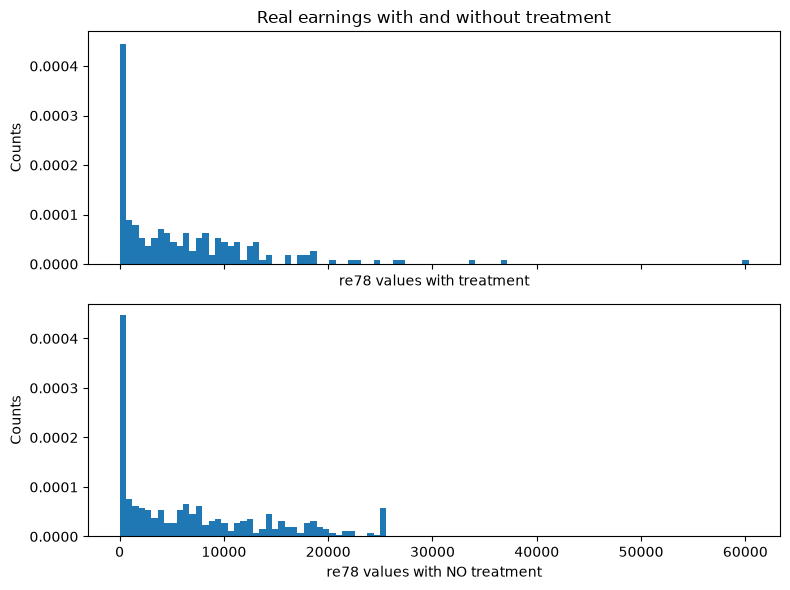

In [ ]:
''' your code and explanations '''
fig, axes = plt.subplots(2, 1, figsize= (8,6), sharex=True, sharey=True)

same_bins = np.linspace(0, df['re78'].max(), 100)

mask_treat78 = df['treat'] == 1
subplot1 = axes[0]
subplot1.hist(df.loc[mask_treat78]['re78'], bins = same_bins, density=True)
#subplot1.hist(df.loc[mask_treat78]['re78'], bins = same_bins)

subplot1.set_xlabel("re78 values with treatment")
subplot1.set_ylabel("Share of people per dollar")
subplot1.set_title("Real earnings with and without treatment")

mask_notreat78 = df['treat'] == 0
subplot2 = axes[1]
subplot2.hist(df.loc[mask_notreat78]['re78'], bins = same_bins, density=True)
#subplot2.hist(df.loc[mask_notreat78]['re78'], bins = same_bins)

subplot2.set_xlabel("re78 values with NO treatment")
subplot2.set_ylabel("Share of people per dollar")

plt.tight_layout()




density=True --> With density=True, matplotlib rescales the heights so that the total area of all bars equals 1:

$$\text{height} = \frac{\text{share of people in the bin}}{\text{bin width}}$$

What matters is that both groups are now on the same scale, so you can compare their shapes even though one group is 2.3 times bigger.

In [39]:
print("All dataset re78 stats: ", df['re78'].describe())

print("\nre 78 with treatment stats: ", df.loc[mask_treat78]['re78'].describe())

print("\nre 78 with NO treatment stats: ", df.loc[mask_notreat78]['re78'].describe())

print("\n Median re 78 with treatment: ", df.loc[mask_treat78]['re78'].median())

print("\n Median re 78 with NO treatment: ", df.loc[mask_notreat78]['re78'].median())



All dataset re78 stats:  count      614.000000
mean      6792.834483
std       7470.730792
min          0.000000
25%        238.283425
50%       4759.018500
75%      10893.592500
max      60307.930000
Name: re78, dtype: float64

re 78 with treatment stats:  count      185.000000
mean      6349.143530
std       7867.402218
min          0.000000
25%        485.229800
50%       4232.309000
75%       9642.999000
max      60307.930000
Name: re78, dtype: float64

re 78 with NO treatment stats:  count      429.000000
mean      6984.169742
std       7294.161791
min          0.000000
25%        220.181300
50%       4975.505000
75%      11688.820000
max      25564.670000
Name: re78, dtype: float64

 Median re 78 with treatment:  4232.309

 Median re 78 with NO treatment:  4975.505


In [42]:
df.groupby('treat')['re78'].median()


treat
0    4975.505
1    4232.309
Name: re78, dtype: float64

In [43]:
df.groupby('treat')['re78'].agg(['mean', 'median', 'std', 'count'])


,mean,median,std,count
treat,,,,
0,6984.169742,4975.505,7294.161791,429
1,6349.143530,4232.309,7867.402218,185


**Interpretation pt 01**
A naive researcher could conclude the treatment doesn't help." Make it more concrete with your numbers. The treated group earns less on average (mean $6,349 vs $6,984, median $4,232 vs $4,976). A naive researcher might even say that the program hurts earnings

The single extreme value (max = $60,308) is in the treated group. That outlier pushes the treated mean up, not the control mean. Without it, the treated mean falls to about $6,056, so the gap gets bigger. What's true is that the control group has more people in the middle and upper range: its 75th percentile is $11,689 vs $9,643. That's why the control group is ahead in both mean and median.

Median of no treatment is higher than with treatment: Median re 78 with NO treatment:  4975.505 vs Median re 78 with treatment:  4232.309


Text(0.5, 1.0, 'Real earnings with and without treatment')

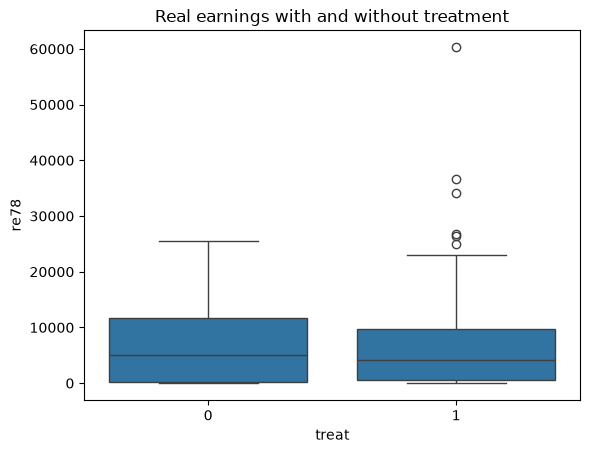

In [40]:
#make boxplot
ax = sns.boxplot(x="treat", y="re78", data=df)
ax.set_title("Real earnings with and without treatment")

Check whether the difference is even significant. The error bars in your barplot overlap a lot. A test confirms it:

In [41]:
#load the statistical libraries
from statsmodels.stats import diagnostic
from scipy import stats

stats.ttest_ind(df.loc[df['treat'] == 1]['re78'], df.loc[df['treat'] == 0]['re78'])

TtestResult(statistic=np.float64(-0.966352225446378), pvalue=np.float64(0.33424966859096517), df=np.float64(612.0))

p-value = 0.3342, so the naive conclusion is weak. The data shows no significant difference between the groups

The key point: why the analysis is "naive". This is what the exercise is building toward. This is observational data: people weren't randomly assigned to the program, so the two groups may differ before the treatment. Without giving away the next part, compare the groups on the other columns (age, black, married, nodegree, re74, re75). df.groupby('treat')[[...]].mean() is enough. 

the naive comparison ignores that the groups may not be comparable, so the difference can't be read as the effect of the treatment.

1. What the numbers show. The treated group earns less in 1978 (mean ≈ $6,350 vs $6,980, median ≈ $4,230 vs $4,980). Both distributions are right-skewed, with about a quarter of people earning $0.

2. The outlier. One treated person earns about $60k, which pulls the treated mean up. Even so, the control group is ahead, and the median, which isn't affected by the outlier, confirms that.

3. The naive conclusion. "The program doesn't help, or even lowers earnings."
4. But the difference isn't significant (t-test p ≈ 0.33).

5. Why it's naive. This is observational data. The groups weren't randomized and may differ before the program (see re74, re75, black, married…), so this comparison can't be read as the effect of the program.

## 2. A closer look at the data

You're not naive, of course (and even if you are, you've learned certain things in ADA), so you aren't content with a superficial analysis such as the above.
You're aware of the dangers of observational studies, so you take a closer look at the data before jumping to conclusions.

For each feature in the dataset, compare its distribution in the treated group with its distribution in the control group, using plots and numbers.
As above, you may use the techniques we discussed in class for summarizing and comparing the distributions.

What do you observe?
Describe what your observations mean for the conclusions drawn by the naive "researcher" from his superficial analysis.

In [4]:
''' your code and explanations ''';

## 3. A propensity score model

Use logistic regression to estimate propensity scores for all points in the dataset.
You may use `statsmodels` to fit the logistic regression model and apply it to each data point to obtain propensity scores.

Recall that the propensity score of a data point represents its probability of receiving the treatment, based on its pre-treatment features (in this case, age, education, pre-treatment income, etc.).
To brush up on propensity scores, you may read chapter 3.3 of the above-cited book by Rosenbaum or [this article](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3144483/pdf/hmbr46-399.pdf).

Note: you do not need a train/test split here. Train and apply the model on the entire dataset. If you're wondering why this is the right thing to do in this situation, recall that the propensity score model is not used in order to make predictions about unseen data. Its sole purpose is to balance the dataset across treatment groups.
(See p. 74 of Rosenbaum's book for an explanation why slight overfitting is even good for propensity scores.
If you want even more information, read [this article](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC3144483/pdf/hmbr46-399.pdf).)

In [5]:
''' your code and explanations ''';

## 4. Balancing the dataset via matching

Use the propensity scores to match each data point from the treated group with exactly one data point from the control group, while ensuring that each data point from the control group is matched with at most one data point from the treated group.
(Hint: you may explore the `networkx` package in Python for predefined matching functions.)

Your matching should maximize the similarity between matched subjects, as captured by their propensity scores.
In other words, the sum (over all matched pairs) of absolute propensity-score differences between the two matched subjects should be minimized.

This is how networkx library can help you do this. Each possible pair of (treated_person, control_person) is characterized by a similarity. This is how we can initialize a graph, and add an edge for one possible pair. We then need to add an edge for each possible pair.
    - G = nx.Graph()
    - G.add_weighted_edges_from([(control_person, treated_person, similarity)])
Optimal matching is then found with:
    - matching = nx.max_weight_matching(G)

After matching, you have as many treated as you have control subjects.
Compare the outcomes (`re78`) between the two groups (treated and control).

Also, compare again the feature-value distributions between the two groups, as you've done in part 2 above, but now only for the matched subjects.
What do you observe?
Are you closer to being able to draw valid conclusions now than you were before?

In [6]:
''' your code and explanations ''';

## 5. Balancing the groups further

Based on your comparison of feature-value distributions from part 4, are you fully satisfied with your matching?
Would you say your dataset is sufficiently balanced?
If not, in what ways could the "balanced" dataset you have obtained still not allow you to draw valid conclusions?

Improve your matching by explicitly making sure that you match only subjects that have the same value for the problematic feature.
Argue with numbers and plots that the two groups (treated and control) are now better balanced than after part 4.


In [7]:
''' your code and explanations ''';

## 6. A less naive analysis

Compare the outcomes (`re78`) between treated and control subjects, as you've done in part 1, but now only for the matched dataset you've obtained from part 5.
What do you conclude about the effectiveness of the job training program?

In [8]:
''' your code and explanations ''';